# Deep Learning Lab Assignment 5 – CNN & Transfer Learning (PyTorch)


In [1]:
import os, glob, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)
torch.manual_seed(42); np.random.seed(42)

Device: cuda


In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not on Colab - skipping Drive mount')

Mounted at /content/drive


In [3]:
# ================= CONFIG =================
ROOT      = '/content/drive/MyDrive/Deep Learning/Lab5/team_17'
IMG_SIZE  = 96
N_BATCHES = 5
CNN_EPOCHS = 100
MLP_EPOCHS, MLP_LR = 100, 1e-3
CACHE     = '/content/drive/MyDrive/Deep Learning/Lab5/cache_%d.npz' % IMG_SIZE

assert os.path.isdir(os.path.join(ROOT, 'train')), f'Path not found: {ROOT}/train - is Drive mounted / upload finished?'
print('Train classes:', sorted(os.listdir(os.path.join(ROOT, 'train'))))
print('Test classes :', sorted(os.listdir(os.path.join(ROOT, 'test'))))

Train classes: ['n01632777', 'n01770081', 'n01770393', 'n01806143', 'n01978287']
Test classes : ['n01632777', 'n01770081', 'n01770393', 'n01806143', 'n01978287']


In [4]:
def load_split(split):
    classes = sorted(d for d in os.listdir(os.path.join(ROOT, split)) if os.path.isdir(os.path.join(ROOT, split, d)))
    paths, labels = [], []
    for i, c in enumerate(classes):
        fs = [f for f in glob.glob(os.path.join(ROOT, split, c, '*')) if f.lower().endswith(('.jpeg','.jpg','.png'))]
        paths += fs; labels += [i]*len(fs)
    def rd(p): return np.asarray(Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE)), dtype=np.uint8)
    with ThreadPoolExecutor(16) as ex: X = np.stack(list(ex.map(rd, paths)))
    return X, np.array(labels), classes

if os.path.exists(CACHE):
    d = np.load(CACHE, allow_pickle=True)
    Xtr, ytr, Xte, yte, classes = d['Xtr'], d['ytr'], d['Xte'], d['yte'], list(d['classes'])
else:
    Xtr, ytr, classes = load_split('train'); Xte, yte, _ = load_split('test')
    np.savez_compressed(CACHE, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, classes=np.array(classes))

names = {'n01632777':'axolotl','n01770081':'harvestman','n01770393':'scorpion','n01806143':'peacock','n01978287':'Dungeness crab'}
class_names = [names.get(c, c) for c in classes]
NUM_CLASSES = len(classes)
print('Classes:', class_names); print('Train:', Xtr.shape, 'Test:', Xte.shape)
print('Total images:', len(Xtr)+len(Xte), '(expected 4214 if upload finished)')
print('Train per class:', np.bincount(ytr), ' Test per class:', np.bincount(yte))

Classes: ['axolotl', 'harvestman', 'scorpion', 'peacock', 'Dungeness crab']
Train: (3501, 96, 96, 3) Test: (700, 96, 96, 3)
Total images: 4201 (expected 4214 if upload finished)
Train per class: [700 700 700 701 700]  Test per class: [140 140 140 140 140]


In [5]:
# uint8 NHWC -> normalised float NCHW tensors on the GPU
mean = torch.tensor([0.485,0.456,0.406], device=device).view(1,3,1,1)
std  = torch.tensor([0.229,0.224,0.225], device=device).view(1,3,1,1)
def to_t(X): return ((torch.from_numpy(X).to(device).permute(0,3,1,2).float()/255.) - mean)/std
Xtr_t, Xte_t = to_t(Xtr), to_t(Xte)
ytr_t, yte_t = torch.from_numpy(ytr).long().to(device), torch.from_numpy(yte).long().to(device)

In [6]:
# ---------- training / evaluation utilities ----------
@torch.no_grad()
def evaluate(model, X, y, bs=512):
    model.eval(); out=[]
    for i in range(0, len(X), bs): out.append(model(X[i:i+bs]))
    logits = torch.cat(out); loss = F.cross_entropy(logits, y).item()
    pred = logits.argmax(1)
    return loss, (pred==y).float().mean().item(), pred.cpu().numpy()

def augment(x):
    flip = torch.rand(x.size(0), device=x.device) < 0.5
    x = torch.where(flip.view(-1,1,1,1), x.flip(3), x)      # random horizontal flip
    dy, dx = torch.randint(-4, 5, (2,)).tolist()
    return torch.roll(x, shifts=(dy, dx), dims=(2, 3))      # small random shift

def train_model(model, Xtr, ytr, Xte, yte, epochs, lr, n_batches=N_BATCHES,
                aug=False, wd=0.0, sched=False):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)   # Adam optimiser
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs) if sched else None
    hist = dict(train_loss=[], test_loss=[], train_acc=[], test_acc=[])
    t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), device=device)
        for idx in torch.tensor_split(perm, n_batches):                  # 5 mini-batches per epoch
            xb = augment(Xtr[idx]) if aug else Xtr[idx]
            opt.zero_grad(); loss = F.cross_entropy(model(xb), ytr[idx]) # CE = softmax + NLL
            loss.backward(); opt.step()
        if sch: sch.step()
        trl, tra, _ = evaluate(model, Xtr, ytr); tel, tea, _ = evaluate(model, Xte, yte)
        for k, v in zip(hist, (trl, tel, tra, tea)): hist[k].append(v)
        if (ep+1) % 10 == 0 or ep == 0:
            print(f'Ep {ep+1:3d} | train loss {trl:.4f} acc {tra:.3f} | test loss {tel:.4f} acc {tea:.3f}')
    print(f'Done in {time.time()-t0:.1f}s'); return hist

def report(title, model, hist, Xte, yte):
    _, acc, pred = evaluate(model, Xte, yte)
    cm = confusion_matrix(yte.cpu().numpy(), pred, labels=range(NUM_CLASSES))
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    ax[0].plot(hist['train_loss'], label='Train'); ax[0].plot(hist['test_loss'], label='Test')
    ax[0].set(title=f'{title}: Error vs Epoch', xlabel='Epoch', ylabel='Cross-entropy error'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(hist['train_acc'], label='Train'); ax[1].plot(hist['test_acc'], label='Test')
    ax[1].set(title=f'{title}: Accuracy vs Epoch', xlabel='Epoch', ylabel='Accuracy'); ax[1].legend(); ax[1].grid(alpha=.3)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax[2], cmap='Blues', colorbar=False, xticks_rotation=45)
    ax[2].set_title(f'{title}: Confusion matrix (test)')
    plt.tight_layout(); plt.savefig(title.replace(' ','_')+'.png', dpi=150); plt.show()
    print(f'{title} -> Test accuracy: {acc*100:.2f}%'); print('Confusion matrix:\n', cm); return acc

## Q1. CNN: CL1(4 maps) → PL1 → CL2(6 maps) → PL2 → softmax
Conv: F=3, S=1, ReLU (padding=1 keeps border information). Max-pool: F=2, S=2. Spatial size is halved by each pooling layer, and the flatten size is computed automatically from IMG_SIZE.

In [7]:
class CNN(nn.Module):
    def __init__(self, bn=False, nc=NUM_CLASSES, size=IMG_SIZE, pad=1):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, stride=1, padding=pad), nn.ReLU()]
            if bn: layers.append(nn.BatchNorm2d(cout))      # post-activation BN (Conv -> ReLU -> BN -> Pool)
            layers.append(nn.MaxPool2d(2, 2)); return layers
        self.features = nn.Sequential(*block(3, 4), *block(4, 6))
        s = size
        for _ in range(2):
            s = ((s + 2*pad - 3) + 1) // 2                  # conv (F=3,S=1) then pool (F=2,S=2)
        self.fc = nn.Linear(6*s*s, nc)                      # softmax is inside the CE loss
    def forward(self, x): return self.fc(self.features(x).flatten(1))

### Q1(a) Without BN and Q1(b) with post-activation BN (Conv → ReLU → BN → Pool)
Each model is trained with 3 seeds. Plots and confusion matrix are from seed 42; reported accuracy is the mean ± std over the 3 seeds.

Ep   1 | train loss 1.5433 acc 0.336 | test loss 1.5443 acc 0.340
Ep  10 | train loss 0.9911 acc 0.617 | test loss 1.0288 acc 0.609
Ep  20 | train loss 0.8684 acc 0.677 | test loss 0.9211 acc 0.680
Ep  30 | train loss 0.8216 acc 0.694 | test loss 0.8992 acc 0.673
Ep  40 | train loss 0.7909 acc 0.700 | test loss 0.8844 acc 0.677
Ep  50 | train loss 0.7661 acc 0.710 | test loss 0.8662 acc 0.681
Ep  60 | train loss 0.7485 acc 0.718 | test loss 0.8620 acc 0.689
Ep  70 | train loss 0.7308 acc 0.721 | test loss 0.8455 acc 0.700
Ep  80 | train loss 0.7248 acc 0.727 | test loss 0.8424 acc 0.704
Ep  90 | train loss 0.7229 acc 0.727 | test loss 0.8437 acc 0.707
Ep 100 | train loss 0.7229 acc 0.726 | test loss 0.8437 acc 0.707
Done in 25.5s


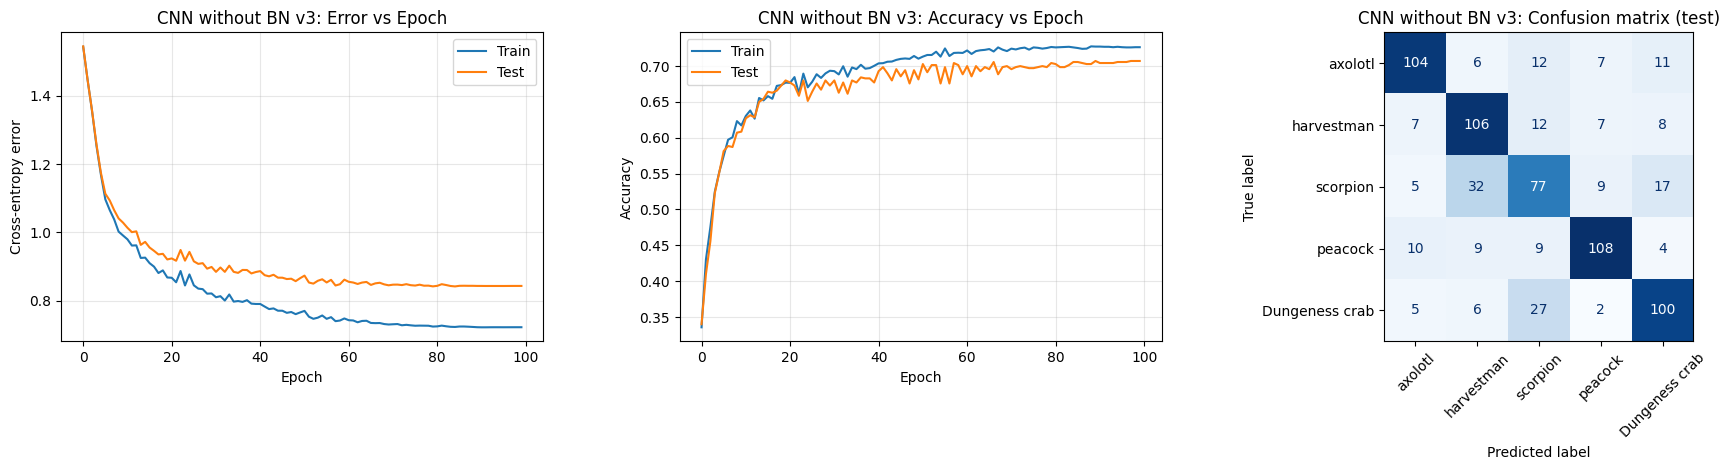

CNN without BN v3 -> Test accuracy: 70.71%
Confusion matrix:
 [[104   6  12   7  11]
 [  7 106  12   7   8]
 [  5  32  77   9  17]
 [ 10   9   9 108   4]
 [  5   6  27   2 100]]
>>> CNN without BN v3 | seed 42 | test acc 70.71%

Ep   1 | train loss 1.5328 acc 0.332 | test loss 1.5357 acc 0.324
Ep  10 | train loss 0.9083 acc 0.656 | test loss 0.9569 acc 0.646
Ep  20 | train loss 0.8286 acc 0.687 | test loss 0.9002 acc 0.671
Ep  30 | train loss 0.7943 acc 0.703 | test loss 0.8764 acc 0.676
Ep  40 | train loss 0.7860 acc 0.710 | test loss 0.8837 acc 0.680
Ep  50 | train loss 0.7630 acc 0.716 | test loss 0.8733 acc 0.690
Ep  60 | train loss 0.7458 acc 0.728 | test loss 0.8686 acc 0.680
Ep  70 | train loss 0.7316 acc 0.733 | test loss 0.8576 acc 0.687
Ep  80 | train loss 0.7304 acc 0.724 | test loss 0.8594 acc 0.683
Ep  90 | train loss 0.7267 acc 0.731 | test loss 0.8571 acc 0.686
Ep 100 | train loss 0.7264 acc 0.731 | test loss 0.8581 acc 0.684
Done in 23.4s
>>> CNN without BN v3 | seed 0 

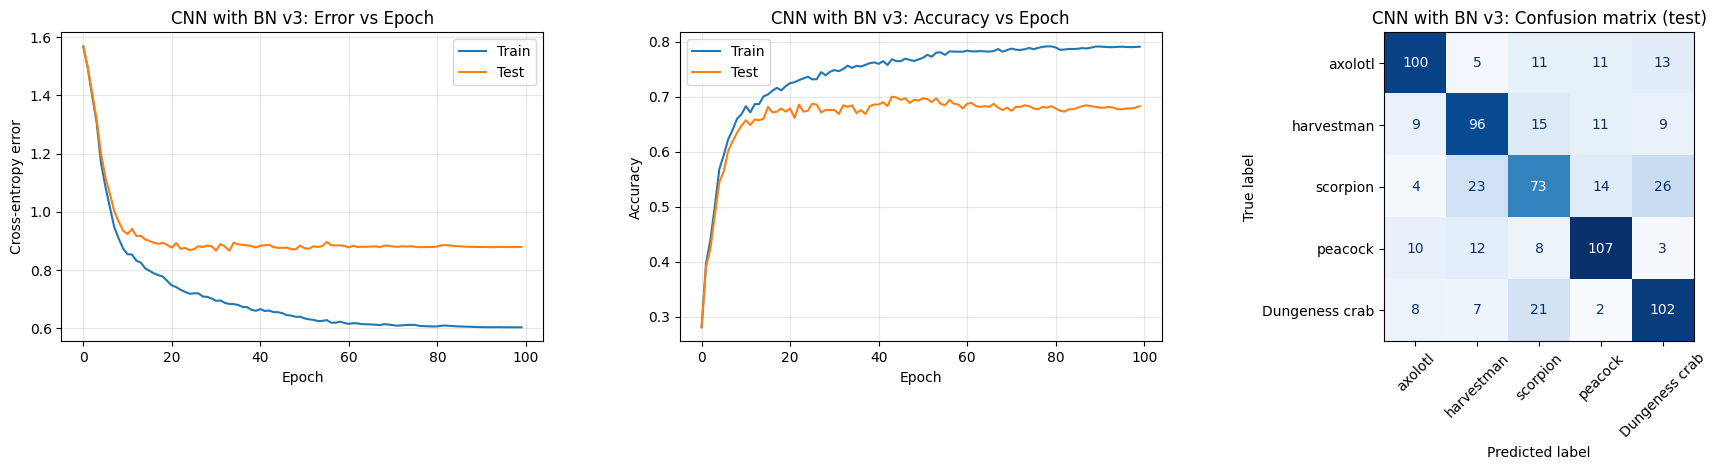

CNN with BN v3 -> Test accuracy: 68.29%
Confusion matrix:
 [[100   5  11  11  13]
 [  9  96  15  11   9]
 [  4  23  73  14  26]
 [ 10  12   8 107   3]
 [  8   7  21   2 102]]
>>> CNN with BN v3 | seed 42 | test acc 68.29%

Ep   1 | train loss 1.5021 acc 0.401 | test loss 1.5042 acc 0.390
Ep  10 | train loss 0.8409 acc 0.684 | test loss 0.9387 acc 0.647
Ep  20 | train loss 0.7606 acc 0.718 | test loss 0.9044 acc 0.674
Ep  30 | train loss 0.7299 acc 0.727 | test loss 0.8706 acc 0.683
Ep  40 | train loss 0.7090 acc 0.741 | test loss 0.8580 acc 0.697
Ep  50 | train loss 0.6921 acc 0.750 | test loss 0.8624 acc 0.693
Ep  60 | train loss 0.6695 acc 0.753 | test loss 0.8521 acc 0.689
Ep  70 | train loss 0.6554 acc 0.759 | test loss 0.8370 acc 0.700
Ep  80 | train loss 0.6528 acc 0.761 | test loss 0.8394 acc 0.700
Ep  90 | train loss 0.6491 acc 0.764 | test loss 0.8346 acc 0.706
Ep 100 | train loss 0.6484 acc 0.766 | test loss 0.8352 acc 0.704
Done in 33.6s
>>> CNN with BN v3 | seed 0 | test ac

In [8]:
SEEDS = [42, 0, 1]

def run_cnn(bn, lr, wd, title):
    accs = []
    for i, sd in enumerate(SEEDS):
        torch.manual_seed(sd)
        m = CNN(bn=bn)
        h = train_model(m, Xtr_t, ytr_t, Xte_t, yte_t, CNN_EPOCHS, lr, aug=True, wd=wd, sched=True)
        if i == 0: accs.append(report(title, m, h, Xte_t, yte_t))
        else:      accs.append(evaluate(m, Xte_t, yte_t)[1])
        print(f'>>> {title} | seed {sd} | test acc {accs[-1]*100:.2f}%\n')
    return np.array(accs)

# Q1(a) without BN
accs_plain = run_cnn(bn=False, lr=2e-3, wd=1e-5, title='CNN without BN v3')
# Q1(b) with post-activation BN
accs_bn = run_cnn(bn=True, lr=1e-3, wd=5e-4, title='CNN with BN v3')

acc1, acc2 = accs_plain.mean(), accs_bn.mean()
print(f'No BN  : {acc1*100:.2f} +/- {accs_plain.std()*100:.2f}  {np.round(accs_plain*100,2)}')
print(f'With BN: {acc2*100:.2f} +/- {accs_bn.std()*100:.2f}  {np.round(accs_bn*100,2)}')

## Q2. Transfer learning: VGG16 (pre-final layer, 4096-d) → PCA → MLFFNN (2 Tanh hidden layers) → softmax
The VGG backbone is frozen, so features are extracted once; only the MLFFNN is trained with Adam in 5 mini-batches.

In [9]:
from torchvision import models
try: vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
except Exception: vgg = models.vgg16(pretrained=True)
vgg.classifier = nn.Sequential(*list(vgg.classifier.children())[:-1])   # drop last FC -> fc7 output (4096-d)
vgg = vgg.to(device).eval()

@torch.no_grad()
def vgg_feats(X, bs=128):
    out=[]
    for i in range(0, len(X), bs):
        xb = F.interpolate(X[i:i+bs], size=224, mode='bilinear', align_corners=False)
        with torch.autocast(device_type=device, enabled=(device=='cuda')): out.append(vgg(xb).float().cpu())
    return torch.cat(out).numpy()

Ftr, Fte = vgg_feats(Xtr_t), vgg_feats(Xte_t)
print('VGG pre-final features:', Ftr.shape, Fte.shape)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 90.7MB/s]


VGG pre-final features: (3501, 4096) (700, 4096)


PCA: 4096 -> 984 dims (95% variance)
Ep   1 | train loss 1.4987 acc 0.484 | test loss 1.5252 acc 0.427
Ep  10 | train loss 0.1458 acc 0.995 | test loss 0.3620 acc 0.909
Ep  20 | train loss 0.0121 acc 1.000 | test loss 0.1733 acc 0.951
Ep  30 | train loss 0.0057 acc 1.000 | test loss 0.1605 acc 0.950
Ep  40 | train loss 0.0035 acc 1.000 | test loss 0.1571 acc 0.949
Ep  50 | train loss 0.0024 acc 1.000 | test loss 0.1561 acc 0.950
Ep  60 | train loss 0.0018 acc 1.000 | test loss 0.1560 acc 0.950
Ep  70 | train loss 0.0014 acc 1.000 | test loss 0.1564 acc 0.950
Ep  80 | train loss 0.0011 acc 1.000 | test loss 0.1571 acc 0.950
Ep  90 | train loss 0.0009 acc 1.000 | test loss 0.1579 acc 0.949
Ep 100 | train loss 0.0007 acc 1.000 | test loss 0.1587 acc 0.949
Done in 1.0s


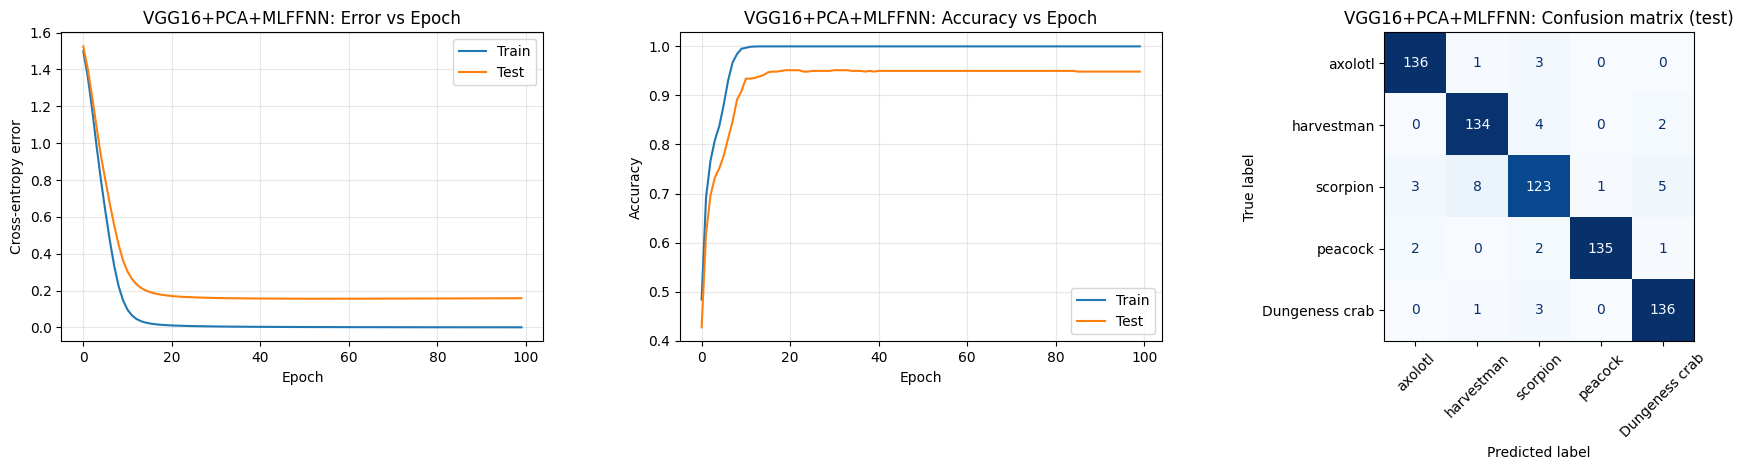

VGG16+PCA+MLFFNN -> Test accuracy: 94.86%
Confusion matrix:
 [[136   1   3   0   0]
 [  0 134   4   0   2]
 [  3   8 123   1   5]
 [  2   0   2 135   1]
 [  0   1   3   0 136]]


In [10]:
# PCA fitted on TRAIN only (95% variance), then standardised for Tanh units
pca = PCA(n_components=0.95, svd_solver='full', random_state=42).fit(Ftr)
sc  = StandardScaler().fit(pca.transform(Ftr))
Ptr = torch.tensor(sc.transform(pca.transform(Ftr)), dtype=torch.float32, device=device)
Pte = torch.tensor(sc.transform(pca.transform(Fte)), dtype=torch.float32, device=device)
print(f'PCA: 4096 -> {Ptr.shape[1]} dims (95% variance)')

class MLFFNN(nn.Module):
    def __init__(self, d_in, h1=256, h2=64, nc=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, h1), nn.Tanh(), nn.Linear(h1, h2), nn.Tanh(), nn.Linear(h2, nc))
    def forward(self, x): return self.net(x)

torch.manual_seed(42)
mlp = MLFFNN(Ptr.shape[1])
h3 = train_model(mlp, Ptr, ytr_t, Pte, yte_t, MLP_EPOCHS, MLP_LR)
acc3 = report('VGG16+PCA+MLFFNN', mlp, h3, Pte, yte_t)

## Summary

In [12]:
import pandas as pd
print(pd.DataFrame({
    'Model': ['CNN without BN', 'CNN with BN', 'VGG16 + PCA + MLFFNN'],
    'Test accuracy (%)': [round(acc1*100, 2), round(acc2*100, 2), round(acc3*100, 2)]
}).to_string(index=False))

               Model  Test accuracy (%)
      CNN without BN              71.00
         CNN with BN              70.57
VGG16 + PCA + MLFFNN              94.86
